# Frame Interpolator

In [29]:
# Please run in your terminal "uv add pytorch-msssim" or "pip install pytorch-msssim"

In [30]:
# Or "uv add -r requirements.txt" or "pip install -r requirements.txt"

In [65]:
import os
import pathlib
import string
import sys
import time
import zipfile
from math import exp

#import cv2
import marimo as mo
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms.functional as TF
from IPython.display import HTML
# https://github.com/VainF/pytorch-msssim?tab=readme-ov-file
from pytorch_msssim import SSIM 
from torch.optim import Adam
from torch.utils.data import DataLoader, Dataset
from torch.utils.tensorboard import SummaryWriter

import fiutils
import mlutils
from model import FrameInterpolator

Here I import the necessary libraries. I also determined the computing device (CUDA or CPU).

In [32]:
device = mlutils.get_device()
print(device)

cuda


## Data Acquisition and Management

This section handles the automated downloading and extraction of the **Vimeo-90K** dataset. I checked if the data exists locally to avoid redundant downloads.

In [33]:
if mlutils.in_lab():
    DATASET_LOCATION = "/transfer/Datasets_Inbetween"
else:
    DATASET_LOCATION = "./Datasets_Inbetween"
print(f"Using {DATASET_LOCATION}")
pathlib.Path(DATASET_LOCATION).mkdir(parents=True, exist_ok=True)

Using /transfer/Datasets_Inbetween


In [34]:
URL = "http://data.csail.mit.edu/tofu/testset/vimeo_interp_test.zip"

dest = DATASET_LOCATION + "/vimeo_interp_test.zip"
if not pathlib.Path(dest).exists():
    mlutils.download(URL, dest)
    with zipfile.ZipFile(dest, "r") as zip_ref:
        zip_ref.extractall(DATASET_LOCATION)

In [35]:
for file in pathlib.Path(DATASET_LOCATION).glob("*"):
    print(file)

/transfer/Datasets_Inbetween/vimeo_interp_test
/transfer/Datasets_Inbetween/vimeo_interp_test.zip


## Data Pre-Processing and Splitting

I parsed the dataset directory to structure the inputs (Image 1, Image 3) and targets (Image 2) into a Pandas DataFrame. This dataframe is then split into **Training (60%)**, **Testing (20%)**, and **Validation (20%)** sets. This splitting ensures I can validate my model on unseen data, preventing overfitting.

In [36]:
DATASET_LOCATION

'/transfer/Datasets_Inbetween'

In [37]:
TARGET_LOCATION = DATASET_LOCATION + "/vimeo_interp_test/target/"
subfolder_list = os.listdir(TARGET_LOCATION)
count = 0
img1_address_list = []  # Input
img2_address_list = []  # Output
img3_address_list = []  # Input
for subfolder in subfolder_list:
    sample_list = os.listdir(TARGET_LOCATION + subfolder)
    for sample in sample_list:
        img1_address_list.append(TARGET_LOCATION + subfolder + "/" + sample + "/im1.png")
        img2_address_list.append(TARGET_LOCATION + subfolder + "/" + sample + "/im2.png")
        img3_address_list.append(TARGET_LOCATION + subfolder + "/" + sample + "/im3.png")

In [38]:
img1_df = pd.DataFrame(img1_address_list, columns=["Image 1 (Input)"])
img3_df = pd.DataFrame(img3_address_list, columns=["Image 3 (Input)"])
img2_df = pd.DataFrame(img2_address_list, columns=["Image 2 (Output)"])
Dataset_df = pd.concat([img1_df, img3_df, img2_df], axis=1)

In [39]:
Dataset_df

,Image 1 (Input),Image 3 (Input),Image 2 (Output)
0,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...
1,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...
2,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...
3,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...
4,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...
...,...,...,...
3777,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...
3778,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...
3779,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...
3780,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...,/transfer/Datasets_Inbetween/vimeo_interp_test...


In [40]:
train_df, test_df, valid_df = np.split(
    Dataset_df.sample(frac=1, random_state=42), [int(0.6 * len(Dataset_df)), int(0.8 * len(Dataset_df))]
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_df = train_df.reset_index(drop=True)

/home/s5725094/Desktop/SEM/ml-programming-assignment-Jazxiou/.venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


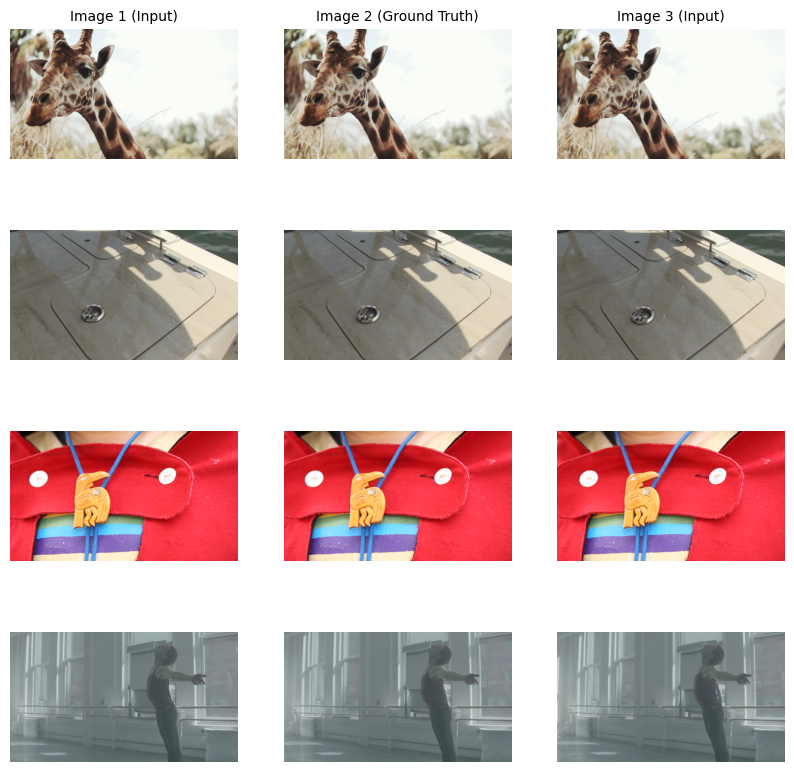

In [41]:
fiutils.plot_dataset_samples(train_df)

## Custom Dataset and DataLoaders

I utilised a `FrameInterpolation` dataset class (defined in `FrameIntUtils.py`) to handle image loading and tensor conversion on-the-fly. Dataloaders are created to batch the data, which optimizes GPU throughout training.

During the data augmentation part from within `fiutils.FrameInterpolation()`, I had to use "if" statements to make sure that a set of 3 images were augmented together and not separately, I couldn't use transforms.RandomHorizontalFlip for example. This also ensures the same level of rotation and colour jitter for each set.

In [42]:
train_data = fiutils.FrameInterpolation(train_df, augment=True)
test_data = fiutils.FrameInterpolation(test_df)
valid_data = fiutils.FrameInterpolation(valid_df)

In [43]:
BATCH_SIZE = 8 # Originally 8, suggested by someone to make it 16 
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE)
valid_loader = DataLoader(valid_data, batch_size=BATCH_SIZE)

In [44]:
next(iter(train_loader))[0][0].shape

torch.Size([8, 3, 256, 448])

In [45]:
next(iter(train_loader))[1].shape

torch.Size([8, 3, 256, 448])

## Model Initialisation

I initialised the `FrameInterpolator` model. This is a CNN designed to compress the input frames into a latent representation and reconstruct the middle frame. We use **SSIM (Structural Similarity Index)** or **MSE** as our loss function to prioritize perceptual quality over simple pixel accuracy.

The model can be found in the model.py file.

In [46]:
model_compiled = FrameInterpolator().to(device)
model_compiled.to(device)

FrameInterpolator(
  (conv1): Sequential(
    (0): Conv2d(6, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (up1): Upsample(scale_factor=2.0, mode='bilinear')
  (dec1): Sequential(
    (0): Conv2d(384, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (up2): Ups

In [47]:
learning_rate = 0.0001
loss_function = nn.L1Loss() # I have also tried MSELoss
optimizer = Adam(model_compiled.parameters(), lr=learning_rate)
accuracy_metric = SSIM(data_range=1.0, size_average=True, channel=3).to(device)

In [48]:
train_N = len(train_loader.dataset)
valid_N = len(valid_loader.dataset)

## Checkpoint

In [49]:
best_model_path = "best_frame_interpolator.pth"
checkpoint_path = "checkpoint.pth"

if os.path.exists(checkpoint_path):
    print("Checkpoint found!")
    checkpoint = torch.load(checkpoint_path) # Load the file
    model_compiled.load_state_dict(checkpoint["model_state_dict"]) # Load model
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"]) # Load the optimiser

    start_epoch = checkpoint["epoch"] + 1
    best_score = checkpoint["best_score"]
    accumulated_time = checkpoint.get("accumulated_time", 0.0)

    # Restore history
    train_loss = checkpoint.get("train_loss", [])
    train_accuracy = checkpoint.get("train_accuracy", [])
    valid_loss = checkpoint.get("valid_loss", [])
    valid_accuracy = checkpoint.get("valid_accuracy", [])
    
    print(f"Resuming from epoch {start_epoch}")
else:
    start_epoch = 0
    best_score = 0.0
    accumulated_time = 0.0
    
    train_loss = []
    train_accuracy = []
    valid_loss = []
    valid_accuracy = []

    print("No checkpoint found.")

Checkpoint found!
Resuming from epoch 135


## Training Loop

For each epoch:
1. **Forward Pass**: Feed inputs through the model.
2. **Loss Calculation**: Compare the prediction to the ground truth.
3. **Backpropagation**: Update weights using the Adam optimiser.
4. **Validation**: Evaluate on the validation set to monitor for generalisation.

I also implemented the **Checkpoint** so that the weights get saved only when the validation loss improves.

In [51]:
# Early stopping to circumvent overfitting
stop_limit = 10
stop_counter = 0

epochs = 0
end_epoch = start_epoch + epochs

total_time = time.time()
print("Training started.")
for epoch in range(start_epoch, end_epoch):
    start_time = time.time()

    # Train
    t_loss, t_accuracy = fiutils.train(
        model_compiled, train_loader, optimizer, loss_function, accuracy_metric, device, train_N
    )
    train_loss.append(t_loss)
    train_accuracy.append(t_accuracy)

    # Validate
    v_loss, v_accuracy = fiutils.validate(model_compiled, valid_loader, loss_function, accuracy_metric, device, valid_N)
    valid_loss.append(v_loss)
    valid_accuracy.append(v_accuracy)

    elapsed_time = time.time() - start_time
    accumulated_time += elapsed_time
    
    # Print
    if epoch%1 == 0: # Every (ideally) 5 epochs
        print(f"Epoch: {epoch + 1}")
        print(f"Train Loss {t_loss:.04f} | Accuracy {t_accuracy:.4f}")
        print(f"Valid Loss {v_loss:.04f} | Accuracy {v_accuracy:.4f}")
        print(f"Elapsed Time: {elapsed_time:.1f}s")

    # Check if best
    if v_accuracy > best_score:
        best_score = v_accuracy
        torch.save(model_compiled.state_dict(), best_model_path)
        print("New Best Model!")
        stop_counter = 0 # Reset counter
    else:
        stop_counter += 1

    # Save checkpoint
    torch.save({
        "epoch": epoch,
        "model_state_dict": model_compiled.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_score": best_score,
        "accumulated_time": accumulated_time,

        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "valid_loss": valid_loss,
        "valid_accuracy": valid_accuracy,
    }, checkpoint_path)

    # Early Stopping
    if stop_counter >= stop_limit:
        print("Model has stopped improving, training will end now.")
        break

    print()

total_elapsed_time = time.time() - total_time
print(f"Training Session Complete. Session Time: {total_elapsed_time / 60:.2f} minutes | Total Project Time: {accumulated_time/60:.2f} minutes")

Training started.
Training Session Complete. Session Time: 0.00 minutes | Total Project Time: 149.43 minutes


### TensorBoard Implementation

Ideally this would have been implemented within the training loop but I was not aware of this in time. I still wanted to show my knowledge and how it could have been implemented.

In [69]:
writer = SummaryWriter("runs/final_model_analysis") # Setup

model_final = FrameInterpolator().to(device)
model_final.load_state_dict(torch.load(best_model_path))
model_final.eval()

# Dummy input to trace the graph
dummy_img1 = torch.randn(1, 3, 256, 256).to(device)
dummy_img3 = torch.randn(1, 3, 256, 256).to(device)
writer.add_graph(model_final, [dummy_img1, dummy_img3])

data_iter = iter(test_loader)
#batch = next(data_iter)
inputs, img2_real = next(data_iter)
img1, img3 = inputs
img1, img3, img2_real = img1.to(device), img3.to(device), img2_real.to(device)

with torch.no_grad():
    img2_pred = model_final(img1, img3)

# Input, Real, Predicted, Input
comparison = torch.cat([img1[:8], img2_real[:8], img2_pred[:8], img3[:8]], dim=3)
grid = torchvision.utils.make_grid(comparison, nrow=1, normalize=True)

writer.add_image("Test_Results/Comparison_Grid", grid, 0)

writer.close()

In [70]:
%load_ext tensorboard
%tensorboard --logdir runs

## Model Analysis

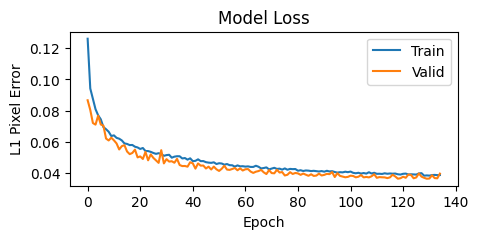

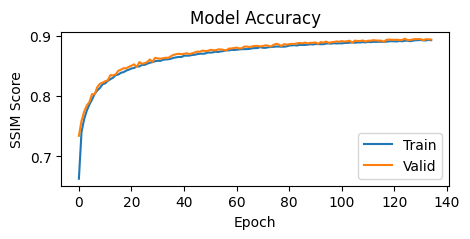

In [52]:
# Loss Graph
plt.figure(figsize=(5, 2))
plt.plot(train_loss, label="Train")
plt.plot(valid_loss, label="Valid")
plt.xlabel("Epoch")
plt.ylabel("L1 Pixel Error")
plt.title("Model Loss")
plt.legend()
plt.show()

# Accuracy Graph
plt.figure(figsize=(5, 2))
plt.plot(train_accuracy, label="Train")
plt.plot(valid_accuracy, label="Valid")
plt.xlabel("Epoch")
plt.ylabel("SSIM Score")
plt.title("Model Accuracy")
plt.legend()
plt.show()

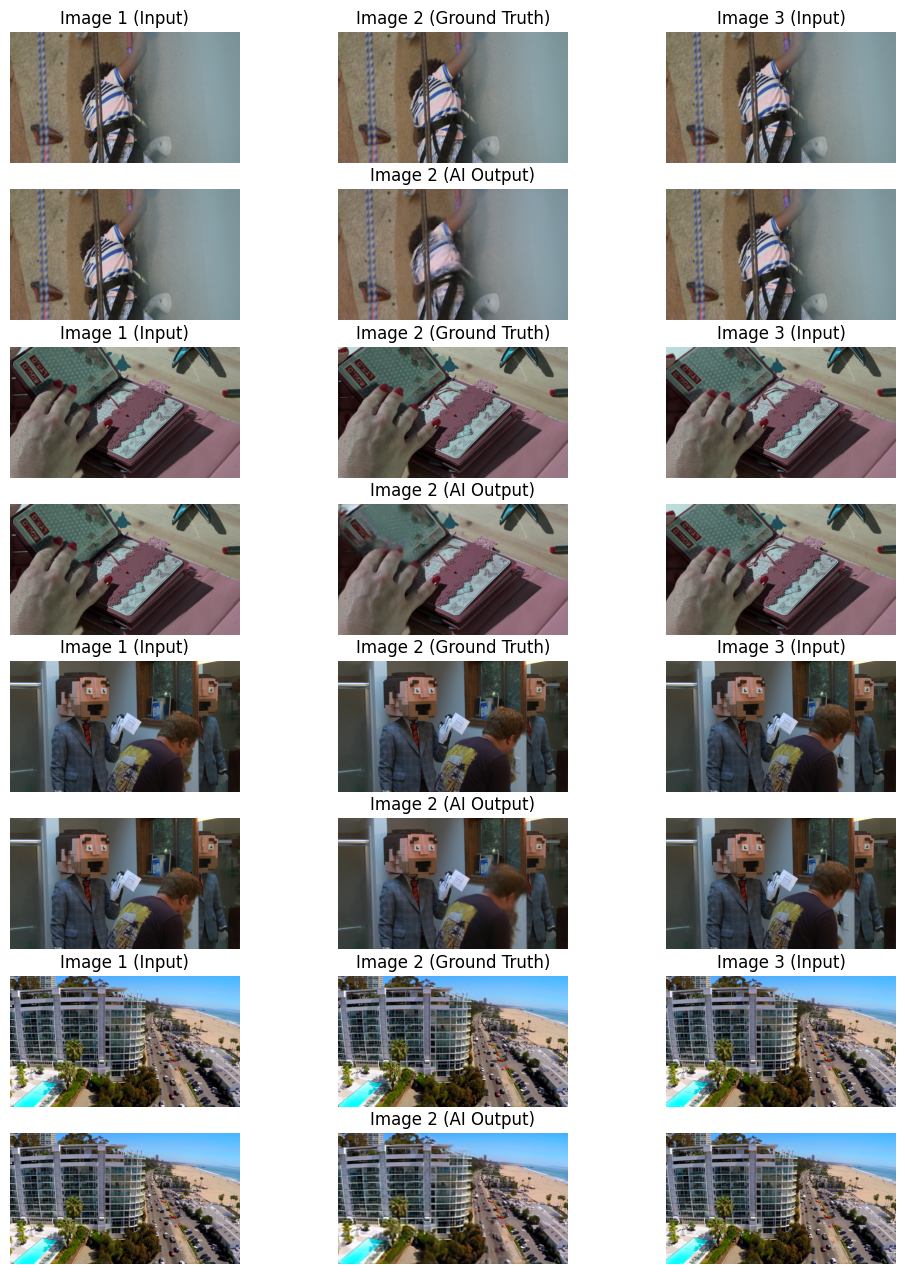

In [64]:
random_test_loader = DataLoader(test_loader.dataset, batch_size=BATCH_SIZE, shuffle=True)
fiutils.plot_results(model_compiled, random_test_loader, device)

In [54]:
fiutils.create_gif(model_compiled, device, dataloader=random_test_loader)

## Testing

### The Speed Test

Testing if my AI could run in real time, this test will help see how many frames per second (FPS) my model could generate.

In [55]:
model_compiled.eval()
dummy_img1 = torch.randn(1, 3, 256, 448).to(device) # My image size
dummy_img3 = torch.randn(1, 3, 256, 448).to(device)

# Warm up GPU
for i in range(10):
    i = model_compiled(dummy_img1, dummy_img3)

torch.cuda.synchronize()

start = time.time()
num_frames = 100
with torch.no_grad():
    for i in range(num_frames):
        i = model_compiled(dummy_img1, dummy_img3)
    torch.cuda.synchronize()
end = time.time()

seconds = end - start
fps = num_frames / seconds

print(f"Inference Speed: {fps:.2f} Frames Per Second")
print(f"Time per frame: {(seconds/num_frames)*1000:.2f} ms")

Inference Speed: 386.54 Frames Per Second
Time per frame: 2.59 ms


### Final Test

I loaded the best-saved model weights and run a final pass on the **Test Set**. This provides an unbiased metric of the model's performance on data it has never seen before.

In [56]:
test_N = len(test_loader.dataset)

model_compiled.load_state_dict(torch.load(best_model_path))

test_time = time.time()
test_loss, test_accuracy = fiutils.validate(model_compiled, test_loader, loss_function, accuracy_metric, device, test_N)
elapsed_test_time = time.time() - test_time

print("Final Test Results")
print(f"Test Loss: {test_loss:.04f} | Test Accuracy: {test_accuracy:.4f} | Time Taken: {elapsed_test_time:.2f}s")

Final Test Results
Test Loss: 0.0369 | Test Accuracy: 0.8945 | Time Taken: 11.94s
